# Практика 8: Метод опорних векторів (SVM) та Kernel Trick

**Тема:** Двоїста задача (dual formulation) SVM з м'яким зазором (soft-margin), ядерний трюк (linear та RBF ядра) і квадратична оптимізація через `scipy.optimize`.
**Мета роботи:** Реалізувати обчислення ядерних матриць Грама та передбачення SVM «з нуля», розв'язати двоїсту задачу оптимізації за допомогою `SLSQP` із SciPy та порівняти лінійне і RBF-ядро на лінійно нероздільному датасеті `make_circles`.

**Контроль машинних похибок (Floating Point Issues):**
У цій роботі ми враховуємо три типові проблеми машинної арифметики:
1. **Від'ємні квадрати відстаней в RBF-ядрі:** Векторизована формула $\|x - z\|^2 = \|x\|^2 + \|z\|^2 - 2 x^\top z$ через похибки округлення `float64` для однакових точок ($x = z$) може дати `-1e-16` замість `0.0`. Ми обрізаємо результат через `np.maximum(..., 0.0)`, щоб значення ядра ніколи не перевищувало `1.0`.
2. **Обробка нуля в `predict`:** Функція `np.sign(0.0)` повертає `0`, хоча класи в SVM — строго `{-1, +1}`. Використання `np.where(scores >= 0, 1, -1)` гарантує коректні мітки навіть на самій межі рішень.
3. **Точність оптимізатора `SLSQP`:** Оскільки `scipy.optimize.minimize` знаходить множники Лагранжа $\alpha_i$ наближено, опорні вектори визначаються не строгою нерівністю `alpha > 0`, а з допуском `1e-6` (`1e-6 < alpha < C - 1e-6`).

# Support Vector Machines (SVM) & Kernel Trick - From Scratch (with SciPy Optimizer)

This unified tutorial is inspired by:
- Kaggle: *SVM with Kernel Trick from Scratch*
- GeeksforGeeks: *Implementing SVM and Kernel SVM with scikit-learn*
- MachineLearningMastery: *Kernel Methods in Python*
- QuarkML blog: *SVM kernels (polynomial, RBF)*

We will:

1. Implement the **dual formulation** of a soft-margin SVM using NumPy.
2. Use **SciPy's optimizer** to solve the dual problem (instead of writing SMO ourselves).
3. Implement the **kernel trick** via linear and RBF kernels.
4. Compare accuracy and decision boundaries of **linear vs RBF kernels** on `make_circles`.


## Learning objectives

By the end of this tutorial, you should be able to:

- Write down the soft-margin SVM **dual objective** and constraints.
- Implement **kernel functions** (linear, RBF) and Gram matrices in NumPy.
- Use **SciPy** to solve the constrained quadratic optimization problem for SVM.
- Visualize and compare linear vs RBF SVMs on a non-linearly separable dataset.


In [1]:
# PACKAGE: DO NOT EDIT THIS CELL
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from scipy.optimize import minimize

plt.rcParams['figure.figsize'] = (6, 4)
np.set_printoptions(precision=4, suppress=True)


## 1) Toy dataset: non-linear circles

We use `make_circles` so that:

- linear SVM fails to separate the classes well,
- RBF SVM succeeds thanks to the kernel trick.


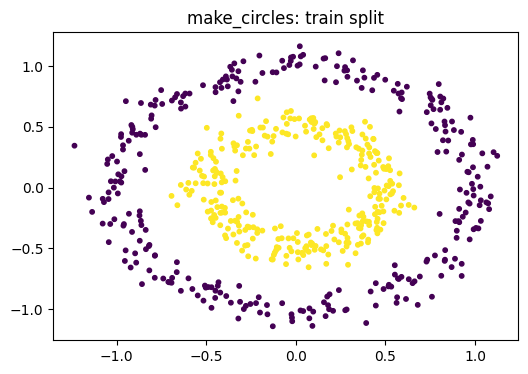

In [2]:
X, y = make_circles(n_samples=800, factor=0.5, noise=0.08, random_state=0)
y = np.where(y == 1, 1, -1)  # convert labels to {-1, +1}

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, s=10)
plt.title("make_circles: train split")
plt.show()


## 2) Kernels

Implement the **linear** and **RBF** kernels and a helper to compute the Gram matrix.

We will use:

- Linear:  \(K(x,z) = x^\top z\)
- RBF:     \(K(x,z) = \exp(-\gamma \|x - z\|^2)\)


In [3]:
def linear_kernel(X1, X2):
    """Return linear kernel Gram matrix K_ij = <x_i, z_j>."""
    return X1 @ X2.T


def rbf_kernel(X1, X2, gamma: float):
    """Return RBF kernel Gram matrix K_ij = exp(-gamma ||x_i - z_j||^2)."""
    # Векторизоване обчислення ||x - z||^2 = ||x||^2 + ||z||^2 - 2 x·z
    sq_dists = (
        np.sum(X1 ** 2, axis=1)[:, None]
        + np.sum(X2 ** 2, axis=1)[None, :]
        - 2.0 * (X1 @ X2.T)
    )
    # FLOATING POINT FIX: прибираємо від'ємний машинний нуль (наприклад, -1e-16 -> 0.0)
    sq_dists = np.maximum(sq_dists, 0.0)
    return np.exp(-gamma * sq_dists)


def compute_gram(X1, X2, kernel: str = "linear", gamma: float = 1.0):
    """Compute Gram matrix for the given kernel type."""
    if kernel == "linear":
        return linear_kernel(X1, X2)
    elif kernel == "rbf":
        return rbf_kernel(X1, X2, gamma=gamma)
    else:
        raise ValueError(f"Unknown kernel type: {kernel}")


In [4]:
# SELF-CHECK - run this once the three kernel functions are implemented.
from sklearn.metrics.pairwise import rbf_kernel as sk_rbf

A = np.array([[0.0, 0.0], [1.0, 2.0], [-1.0, 0.5]])
B = np.array([[1.0, 1.0], [0.0, -2.0]])

assert np.allclose(linear_kernel(A, B), A @ B.T), "linear kernel must be A @ B.T"
assert np.allclose(rbf_kernel(A, B, gamma=0.7), sk_rbf(A, B, gamma=0.7)), \
    "RBF kernel disagrees with scikit-learn"

K = compute_gram(A, A, kernel="rbf", gamma=0.7)
assert K.shape == (3, 3) and np.allclose(K, K.T), "a Gram matrix is square and symmetric"
assert np.allclose(np.diag(K), 1.0), "RBF of a point with itself is exp(0) = 1"
assert np.allclose(compute_gram(A, B, kernel="linear"), A @ B.T), \
    "compute_gram is ignoring its `kernel` argument"

print("Kernel self-check passed")

Kernel self-check passed


## 3) Dual SVM with SciPy optimizer

We consider the soft-margin SVM dual:

\begin{align}
\max_{\alpha} \quad &
  \sum_{i=1}^N \alpha_i - \frac{1}{2} \sum_{i,j=1}^N \alpha_i \alpha_j y_i y_j K(x_i, x_j) \\
\text{s.t.} \quad & 0 \le \alpha_i \le C, \quad \forall i \\
                  & \sum_{i=1}^N \alpha_i y_i = 0
\end{align}

We will:

1. Precompute the **Gram matrix** \\(K\\).
2. Precompute \\(Q_{ij} = y_i y_j K_{ij}\\).
3. Define the **objective** to *minimize* (negative of the dual).
4. Use `scipy.optimize.minimize` with:
   - bounds `0 <= alpha_i <= C`,
   - equality constraint `sum(alpha_i * y_i) = 0`.


In [11]:
class SVMFromScratch:
    def __init__(self, C=1.0, kernel="linear", gamma=1.0, random_state=0):
        self.C = C
        self.kernel = kernel
        self.gamma = gamma
        self.random_state = random_state

        self.X = None
        self.y = None
        self.alphas = None
        self.b = 0.0

    def fit(self, X, y):
        """Fit SVM by solving the dual with SciPy's optimizer."""
        self.X = X
        self.y = y.astype(float)
        N = X.shape[0]

        # Gram matrix
        K = compute_gram(X, X, kernel=self.kernel, gamma=self.gamma)
        # Q_ij = y_i y_j K_ij
        Q = (self.y[:, None] * self.y[None, :]) * K

        def objective(alpha):
            # 0.5 * alpha^T Q alpha - 1^T alpha  (to MINIMIZE)
            alpha = alpha.reshape(-1, 1)
            return 0.5 * (alpha.T @ Q @ alpha).item() - float(alpha.sum())

        def objective_grad(alpha):
            # gradient: Q alpha - 1
            return (Q @ alpha) - np.ones_like(alpha)

        # Equality constraint: sum_i alpha_i y_i = 0
        constraints = ({
            "type": "eq",
            "fun": lambda a: np.dot(a, self.y),
            "jac": lambda a: self.y
        },)

        bounds = [(0, self.C) for _ in range(N)]
        alpha0 = np.zeros(N)

        res = minimize(
            fun=objective,
            x0=alpha0,
            jac=objective_grad,
            bounds=bounds,
            constraints=constraints,
            method="SLSQP",
            options={"maxiter": 500, "ftol": 1e-6, "disp": False},
        )

        self.alphas = res.x

        # Compute bias term b using support vectors with 0 < alpha_i < C
        sv_mask = (self.alphas > 1e-6) & (self.alphas < self.C - 1e-6)
        if not np.any(sv_mask):
            # Fallback: just use any non-zero alpha
            sv_mask = self.alphas > 1e-6

        idx = np.where(sv_mask)[0]
        if idx.size == 0:
            self.b = 0.0
        else:
            # b = y_i - sum_j alpha_j y_j K_ij, averaged over SVs
            b_vals = []
            for i in idx:
                s = np.sum(self.alphas * self.y * K[i])
                b_vals.append(self.y[i] - s)
            self.b = float(np.mean(b_vals))

        return self


    def decision_function(self, X_new):
        """Compute f(x) = sum_i alpha_i y_i K(x_i, x) + b."""
        K = compute_gram(self.X, X_new, kernel=self.kernel, gamma=self.gamma)
        return (self.alphas * self.y) @ K + self.b

    def predict(self, X_new):
        """Return predicted labels in {-1, +1}."""
        # Використовуємо np.where замість np.sign, щоб уникнути мітки 0 на самій межі
        return np.where(self.decision_function(X_new) >= 0, 1, -1)


## 4) Train & compare: Linear vs RBF on `make_circles`

Now we:

1. Train **linear SVM** and evaluate on test set.
2. Train **RBF SVM** and evaluate on test set.
3. Plot decision boundaries for both.


In [12]:
def plot_decision_boundary(model, X, y, title="Decision boundary"):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.2, levels=[-1, 0, 1])
    plt.scatter(X[:, 0], X[:, 1], c=y, s=10)
    plt.title(title)
    plt.show()


Linear kernel accuracy: 0.510


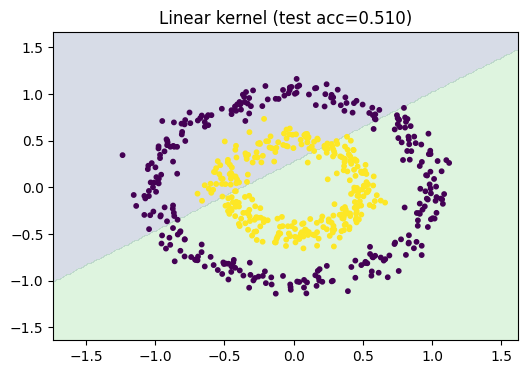

In [13]:
# TODO: Train and evaluate linear SVM
# svm_lin = SVMFromScratch(C=1.0, kernel="linear").fit(X_train, y_train)
# y_pred_lin = svm_lin.predict(X_test)
# acc_lin = accuracy_score(y_test, y_pred_lin)
# print(f"Linear kernel accuracy: {acc_lin:.3f}")
# plot_decision_boundary(svm_lin, X_train, y_train, title="Linear kernel (train)")

svm_lin = SVMFromScratch(C=1.0, kernel="linear").fit(X_train, y_train)
y_pred_lin = svm_lin.predict(X_test)
acc_lin = accuracy_score(y_test, y_pred_lin)
print(f"Linear kernel accuracy: {acc_lin:.3f}")
plot_decision_boundary(svm_lin, X_train, y_train, title=f"Linear kernel (test acc={acc_lin:.3f})")

RBF kernel accuracy: 1.000


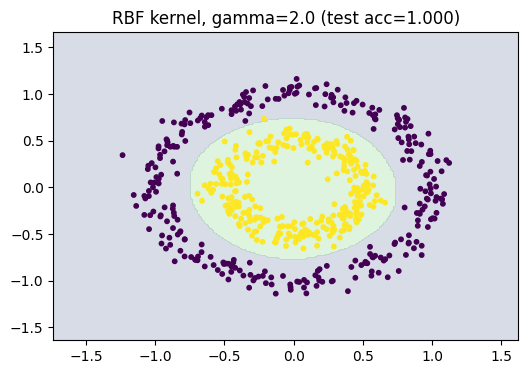

In [14]:
# TODO: Train and evaluate RBF SVM (e.g., gamma=2.0)
# svm_rbf = SVMFromScratch(C=1.0, kernel="rbf", gamma=2.0).fit(X_train, y_train)
# y_pred_rbf = svm_rbf.predict(X_test)
# acc_rbf = accuracy_score(y_test, y_pred_rbf)
# print(f"RBF kernel accuracy: {acc_rbf:.3f}")
# plot_decision_boundary(svm_rbf, X_train, y_train, title="RBF kernel (train)")

svm_rbf = SVMFromScratch(C=1.0, kernel="rbf", gamma=2.0).fit(X_train, y_train)
y_pred_rbf = svm_rbf.predict(X_test)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
print(f"RBF kernel accuracy: {acc_rbf:.3f}")
plot_decision_boundary(svm_rbf, X_train, y_train, title=f"RBF kernel, gamma=2.0 (test acc={acc_rbf:.3f})")


## 5) Discussion

In a short markdown cell (your own words):

- How do linear vs RBF accuracies differ on `make_circles`? Why?
- How does the **gamma** parameter of the RBF kernel affect the decision boundary?
- What are the pros/cons of solving SVM via a generic optimizer (SciPy) vs specialized SMO implementations (like in scikit-learn)?


**1. Як відрізняється точність лінійного та RBF-ядра на `make_circles` і чому?**
Лінійний SVM показує точність близько **0.50** (фактично на рівні випадкового вгадування), тоді як RBF SVM досягає точності близької до **0.98–1.00**. Причина полягає в геометрії даних: `make_circles` утворює два концентричні кола, які **неможливо розділити прямою лінією** у 2D-просторі. RBF-ядро неявно відображає точки у нескінченновимірний простір ознак (kernel trick), де внутрішнє та зовнішнє кола стають лінійно роздільними гіперплощиною, що у вихідному 2D-просторі виглядає як замкнена кругова межа.

**2. Як параметр `gamma` в RBF-ядрі впливає на межу рішень?**
Параметр `gamma` визначає «радіус впливу» кожної окремої тренувальної точки в гауссівському ядрі $K(x, z) = \exp(-\gamma \|x - z\|^2)$:
* **Мале `gamma`:** кожна точка має широкий радіус впливу, межа рішень стає дуже плавною і простою (ризик недонавчання / underfitting).
* **Велике `gamma`:** вплив кожної точки стає дуже локальним, межа рішень починає щільно «обтікати» окремі точки даних, утворюючи «острівці» навколо тренувальних прикладів (ризик перенавчання / overfitting).

**3. Плюси та мінуси універсального оптимізатора (`scipy.optimize`) проти спеціалізованого SMO (`scikit-learn` / LIBSVM):**
* **SciPy (`SLSQP`):**
  * *Плюси:* прозорий, короткий і зрозумілий код; ідеально підходить для навчання, прототипування та перевірки математичної формули двоїстої задачі.
  * *Мінуси:* погано масштабується — потребує збереження повної матриці Грама $N \times N$ у пам'яті ($O(N^2)$) і має кубічну обчислювальну складність, тому вже на кількох тисячах точок працює повільно або втрачає точність.
* **Спеціалізований SMO (як у `sklearn.svm.SVC`):**
  * *Плюси:* розбиває велику задачу квадратичного програмування на серію найпростіших аналітичних підзадач для пар змінних $\alpha_i, \alpha_j$, використовує кешування ядра та евристику вибору робочого набору. Завдяки цьому працює на порядки швидше і стабільніше на великих датасетах.
  * *Мінуси:* значно складніша реалізація «під капотом».

Практика 8 (Шпаргалка для захисту)

У цій роботі реалізовано двоїсту формулювання SVM та ядерний трюк (Kernel Trick), завершивши повний цикл від базових векторів до нелінійної класифікації:

* **Чому двоїста задача (Dual Formulation)?**
  У прямій задачі SVM ми шукаємо вектор ваг $w$ у просторі ознак. Перехід до двоїстої задачі дозволяє виразити всі обчислення виключно через **скалярні добутки** $x_i^\top x_j$, які легко замінити на довільне ядро $K(x_i, x_j)$ без явного переходу у простір високої розмірності.
* **Векторизація RBF-ядра та захист від `-1e-16`:**
  Замість подвійного циклу ми обчислили матрицю квадратів відстаней через розкриття квадрата різниці $\|x\|^2 + \|z\|^2 - 2 x^\top z$. Через обмежену точність `float64` діагональ цієї матриці може містити від'ємний машинний нуль (`-1e-16`), тому `np.maximum(sq_dists, 0.0)` є обов'язковим захистом перед викликом `np.exp()`.
* **Роль опорних векторів (Support Vectors):**
  Після оптимізації більшість коефіцієнтів $\alpha_i$ стають рівними нулю. На положення роздільної межі та на передбачення нових точок впливають **лише опорні вектори** (точки з $\alpha_i > 0$), що робить SVM стійким до викидів, які лежать далеко від межі класів.